# 05. Slung-load model validation (offline, taut point load)

**MRAC-RL logbook, step 1 of 4.** The four logbook steps, read in order, are notebooks 05, 06, 08 and 07. This notebook validates the offline Newton-Euler model on which the MRAC work is built; the later steps use that model.

> **EXPLORATORY / offline / PROXY.** Everything here runs on the reduced taut point-load model (`QuadLoadPend`, development PC). It makes no stability claim, no claim about the Pymunk chain plant and no hardware claim. Theory source: **MQP**, the thesis derivation note *MRAC for a planar quadrotor with a cable-suspended payload* (file `.ai/research/derivations/mrac-quadrotor-payload.md` in the thesis repository; status PROPOSED, not accepted). "MQP §x" below means section x of that note. You do not need the file to follow this notebook: the key steps are derived here.

> **Scope (code angle, offset plant).** This notebook works in the code coordinates (the cable angle $\phi_{code}$) at the canonical attachment offset $d=0.3795$ m. The simple sign flip to the residual.tex angle is **not** applied here (see the notation cell below).

**Terms used in this notebook** (the full glossary is in `00_Notation_and_Reading_Guide.ipynb`):

| Term | Meaning here |
|---|---|
| taut point-load model | a point payload $m_L$ hanging on a massless rigid cable of length $l$ that is always under tension $T>0$ (no slack) |
| `QuadLoadPend` | the code name of this model (vehicle plus pendulum payload) |
| $d$ | distance from the vehicle centre of mass to the cable attachment point, along the body-down axis |
| Fact 1 | the property that, for a *prescribed* vehicle motion, the cable angle $\phi(t)$ does not depend on $m_L$ (derived in section 4.5) |
| arms 1-3 | the three controller families of the MRAC plan: arm 1 is PID+FF (PID plus feedforward) with a feedforward that is blind to the payload mass (it assumes the 4 kg nominal), arm 2 adds the softer swing law plus a linear damper, arm 3 is arm 2 plus MRAC (model reference adaptive control). They are built in notebooks 06 and 07 |
| A0 | the first MRAC architecture of the plan (MQP §1.2): a nominal reference closed loop and the real plant run in parallel and an adaptive law makes the plant follow the reference (notebook 07) |
| PROXY, EXPLORATORY | labels for development-PC offline results: they are evidence about a reduced model only, never about the Pymunk chain plant or hardware |


### Notation used across this series (added 2026-11-25)

The thesis notation (`thesis_book/residual.tex`, lines 95-292) is primary. The code and the derivation document (MQP) use their own symbols, mapped in the thesis file `.ai/research/derivations/notation-residual-tex.md`.

| This notebook / code | residual.tex | Note |
|---|---|---|
| `m_L`, `l` | $m_b$, $\ell$ | payload mass, rope length |
| `m_q`, `J`; `f`, `tau` | $m_q$, $J_q$; $f_q$, $\tau_q$ | |
| `phi` (code) | $\varphi$ | **$\varphi_{\rm tex} = -\varphi_{\rm code}$** with the cable at the vehicle CoG ($d = 0$). Odd functions of $\varphi$ flip sign; $\cos\varphi$, the tension and the tangent do not. With an offset $d\ne0$ the map is nonlinear |
| task reference `p_r(t)` | $x^d$ ("reference state" in residual.tex) | not Guha's reference model $x_r$ |

Numbers in this notebook are unchanged; only the reading of the symbols is aligned.

### Offset-plant angle scope
Offset-plant results in this notebook, including analyses at the canonical $d=0.3795\,\mathrm{m}$, use the **code-angle convention** $\phi_{code}$. The simple residual.tex sign conversion $\varphi_{tex}=-\varphi_{code}$ applies only at $d=0$; at any nonzero offset the map is nonlinear and that sign rule is **not valid**. Any $d$ sweep uses the values shown in its labels. Numerical data and plotted values remain in their original code coordinates and were not transformed.


## 1. Research question

Before any controller is compared, is the offline plant itself trustworthy? Concretely:

1. Does the eliminated model have the right **hover equilibrium** for every payload mass, cable length and attachment offset?
2. Does it obey the **power balance** $\dot E = f\,b(\theta)^{\top}v+\tau\,\omega$ (the cable does no net work)?
3. Does it reproduce the **two classical swing frequencies** (vehicle held fixed: $g/l$; vehicle free: $(g/l)(1+m_L/m_q)$)?
4. Does the swing equation give **Fact 1** (the name used in the MRAC plan for this property): for a *prescribed* vehicle motion, $\phi(t)$ does not depend on $m_L$ (but does on $l$)? A length mismatch between plant and reference breaks it (the plan calls that Fact 2, used in notebook 09).
5. What does the model do when the cable would go **slack** (the taut-domain exit)?

## 2. Hypotheses and predicted direction

Stated before looking at any number below (tolerances in the quantitative table, section 7).

| # | Hypothesis | Predicted result |
|---|---|---|
| H1 | Hover with thrust $(m_q+m_L)g$ is an equilibrium for all $(m_L,l,d)$ | all accelerations and $T-m_Lg$ at round-off ($\sim10^{-14}$) |
| H2 | The instantaneous identity $\dot E=P_{\rm in}$ holds at random states; along a trajectory the balance closes up to the quadrature error of $\int P\,dt$ | residual $\sim10^{-15}$ (identity); trajectory residual falls like $T_s^{2}$ for the trapezoid rule |
| H3 | Measured swing frequencies equal $\sqrt{g/l}$ and $\sqrt{(g/l)(1+m_L/m_q)}$ | agreement to the small-amplitude error $\phi_0^2/16$ for the first; $<10^{-5}$ relative for the ratio |
| H4 | For a prescribed vehicle trajectory $\phi(t)$ is identical for $m_L=2,4,6$ kg and changes with $l$; $T$ scales with $m_L$. For the open-loop plant the swing depends on $m_L$ only through $d>0$ | $\max|\Delta\phi|=0$ to integration tolerance (structural, section 4); open-loop plant: nonzero for the canonical $d$, zero for $d=0$ |
| H5 | In a uniformly accelerating frame the cable lags at $\phi_{eq}=-\arctan\!\big(a_y/(g+a_z)\big)$ with $T=m_L\sqrt{a_y^2+(g+a_z)^2}$; the taut model exits when $T\to0$ | closed form matches the model at round-off |

## 3. Experiment identity

In [1]:
%matplotlib inline
import dataclasses, math
from functools import lru_cache

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from scipy.integrate import solve_ivp, simpson, cumulative_trapezoid

from mrac_lab import provenance, style, plots, widgets

prov = provenance.setup(pinned_commit="2a329ad")   # thesis checkout: $MRAC_THESIS_ROOT or the main checkout (Claude branch)
style.init()                       # thesis 'screen' style preset, inline matplotlib

from experiments.mrac.quad import QuadParams, QuadState, Timing
from experiments.mrac.quad_load_pend import (
    PayloadParams, QuadLoadState, QuadLoadPend, TautDomainExit,
    load_position, load_velocity, attachment_direction, attachment_tangent,
    cable_direction, cable_tangent, tension_and_swing, taut_accelerations,
)

In [2]:
# ---- vehicle parameters ------------------------------------------------------------------
from experiments.mrac.baselines import canonical_offline_params
CANON = canonical_offline_params()               # Pymunk canonical values, each with its source
VEH = CANON.quad
G = VEH.g
D_CANON = CANON.payload.d                        # canonical attachment offset (half the vehicle height)
SOURCES = {r.name + " [" + r.unit + "]": "%s  <- %s" % (r.value, r.source) for r in CANON.records}

TIMING = CANON.timing                    # control dt = 1/50 s, N = 10 substeps (sim_dt = 1/500 s)
T_S = TIMING.T_s
provenance.banner(prov, "05 Slung-load model validation", SOURCES,
                  notes=list(CANON.caveats) + ["Cable model difference: Pymunk uses an 8-segment chain; this model is a taut point mass.",
                         "Frame: z-up, gravity (0, -g); phi measured from the downward vertical; q(phi) = [sin phi, -cos phi]."])

05 Slung-load model validation
Label: EXPLORATORY / offline / PROXY (development PC, reduced taut point-load model)
Thesis checkout: C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load
Commit: 2a329ad957367fc1bc2613f268b1c37b040b7d48 (branch Claude, WORKING TREE HAS UNCOMMITTED CHANGES under experiments/ or gym_pymunk_quadrotor/)
Python: 3.12.3
Claim limits: No stability claim, no Pymunk-transfer claim, no hardware claim. Offline metrics are named *_off and are not the canonical c_T / c_S.
import origin: experiments.mrac.quad -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load\experiments\mrac\quad.py
import origin: experiments.mrac.quad_load_pend -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load\experiments\mrac\quad_load_pend.py
import origin: experiments.notebook_utils.style -> C:\Users\Jc

m_q [kg],9.6 <- gym_pymunk_quadrotor/plant/config.py:61
width [m],1.164 <- gym_pymunk_quadrotor/plant/config.py:62
height [m],0.759 <- gym_pymunk_quadrotor/plant/config.py:63
J [kg m^2],1.5447816 <- gym_pymunk_quadrotor/plant/entities/quadrotor.py:94-95 (m (w^2+h^2)/12)
a_p = a_n [m],"0.582 <- gym_pymunk_quadrotor/plant/entities/quadrotor.py:96-97,301 (width/2)"
vehicle max_thrust (total) [N],"201.036 <- gym_pymunk_quadrotor/plant/entities/quadrotor.py:157-159 ((m+max_payload) g + m max_ascent_speed; config.py:66,69)"
T_max (per motor) [N],100.518 <- gym_pymunk_quadrotor/plant/entities/quadrotor.py:300; plant/entities/motor.py:135 (thrust = max_thrust_per_motor cmd^2)
tau_m [s],0.05 <- gym_pymunk_quadrotor/plant/config.py:72; motor.py:92-93 (first-order lag)
g [m/s^2],9.81 <- gym_pymunk_quadrotor/config/physics_legacy.py:25
kappa_L = kappa_R [-],1.0 <- no effectiveness split in Pymunk
d [m],"0.3795 <- gym_pymunk_quadrotor/plant/xpbd_cable.py:330-333 (pivot_local = (0, -height/2): cable leaves the bottom edge)"


## 4. Theory

> **Where this comes from.**
> * **Source:** MQP §5 (the taut point-load plant, steps 1-9): §5.1 geometry and kinematics, §5.2 projections, §5.3 Newton-Euler balances, §5.4 tension, §5.5 swing, §5.6 elimination, §5.7 limits (hover, frequencies). The power balance and the accelerating-frame result are re-derived below from the same equations.
> * **Prerequisites:** planar rigid-body mechanics. No earlier notebook of the series is needed; the symbols are in `00_Notation_and_Reading_Guide.ipynb`.
> * **Assumptions:**
>   1. massless, rigid cable of fixed length $l$ (inextensible, no mass, no drag);
>   2. point payload of mass $m_L>0$;
>   3. the cable is taut, $T>0$, and the motion is smooth (no slack, no impact);
>   4. the attachment point is fixed in the vehicle body at distance $d$ below the centre of mass, along the body-down direction;
>   5. planar Newton-Euler vehicle (mass $m_q$, inertia $J$) driven by a thrust $f$ along the body axis and a moment $\tau$;
>   6. no wind, drag or contact.
>
>   These are model assumptions; they are not verified properties of the Pymunk chain plant.

### 4.1 Frame, geometry and kinematics (MQP §2.1 conventions, §5.1)

The world frame is planar and z-up: $y$ horizontal, $z$ vertical, gravity $(0,-g)$, $e_z=[0,1]^{\top}$. The vehicle attitude $\theta$ is positive counter-clockwise; $\phi$ is the cable angle **in the world frame**, measured from the downward vertical. All of $p=[y,z]^{\top}$, $v$, $\ddot p$ are 2-vectors. The unit vectors (all 2-vectors, dimensionless) are
$$
b(\theta)=\begin{bmatrix}-\sin\theta\\ \cos\theta\end{bmatrix}\ \text{(thrust, body up)},\quad
n(\theta)=\begin{bmatrix}\sin\theta\\ -\cos\theta\end{bmatrix}=-b\ \text{(body down)},\quad
m(\theta)=\frac{dn}{d\theta}=\begin{bmatrix}\cos\theta\\ \sin\theta\end{bmatrix},
$$
$$
q(\phi)=\begin{bmatrix}\sin\phi\\ -\cos\phi\end{bmatrix}\ \text{(vehicle to payload)},\quad
t(\phi)=\frac{dq}{d\phi}=\begin{bmatrix}\cos\phi\\ \sin\phi\end{bmatrix}\ \text{(tangent)},\quad
\sigma=\sin(\phi-\theta),\ \ \gamma=\cos(\phi-\theta).
$$
Two derivative facts follow by differentiating the components: $dm/d\theta=-n$ and $dt/d\phi=-q$.

**Step 1 (positions).** The attachment point is $p_a=p+d\,n(\theta)$ and the payload is $p_L=p_a+l\,q(\phi)$.

**Step 2 (velocities).** Differentiate with the chain rule ($dn/d\theta=m$, $dq/d\phi=t$): $v_a=v+d\dot\theta\,m(\theta)$ and $v_L=v_a+l\dot\phi\,t(\phi)$.

**Step 3 (accelerations).** Differentiate once more and use $dm/d\theta=-n$, $dt/d\phi=-q$:
$$
\ddot p_a=\ddot p+d\ddot\theta\,m(\theta)-d\dot\theta^{2}n(\theta),\qquad
\ddot p_L=\ddot p_a+l\ddot\phi\,t(\phi)-l\dot\phi^{2}q(\phi).
$$
The three terms of each line are the tangential acceleration and the centripetal acceleration of a point on a rotating arm of length $d$ (respectively $l$).

**Step 4 (projection identities, MQP §5.2).** Each is a product of sines and cosines, for example $q^{\top}m=\sin\phi\cos\theta-\cos\phi\sin\theta=\sin(\phi-\theta)$:
$$
q^{\top}m=\sigma,\quad q^{\top}n=\gamma,\quad q^{\top}t=0,\quad t^{\top}m=\gamma,\quad t^{\top}n=-\sigma,\quad e_z^{\top}q=-\cos\phi,\quad e_z^{\top}t=\sin\phi .
$$


### 4.2 Newton-Euler balances for the vehicle and the payload (MQP §5.3)

The cable is massless, so it transmits one force along its own direction: it pulls the vehicle towards the payload with $T\,q$ and the payload back with $-T\,q$ (equal and opposite), where $T>0$ is the tension (taut domain). Newton's second law for each body:
$$
m_q\ddot p=f\,b(\theta)+T\,q-m_q g\,e_z,\qquad
m_L\ddot p_L=-T\,q-m_L g\,e_z,\qquad
J\ddot\theta=\tau+d\,T\,\sigma .
$$
* First line: vehicle, thrust $f$ along the body axis, cable pull, gravity.
* Second line: payload, cable pull and gravity only.
* Third line: rotation of the vehicle. The cable force $Tq$ acts at the attachment point, a lever arm $d\,n(\theta)$ from the centre of mass, so its moment is the 2D cross product $(d\,n)\times(T\,q)=dT\,(n_y q_z-n_zq_y)=dT(-\sin\theta\cos\phi+\cos\theta\sin\phi)=dT\sin(\phi-\theta)=dT\sigma$.

The unknowns are $\ddot p$ (2), $\ddot\theta$, $\ddot\phi$ and $T$: five numbers, and the equations give five scalar equations (2 + 1 + 2), once $\ddot p_L$ is written through the kinematics of section 4.1. The next two subsections split the payload equation into its component **along** the cable (which gives $T$) and **across** the cable (which gives the swing).

### 4.3 Radial and tangential projections: tension and swing (MQP §5.4, §5.5)

**Radial (tension).** Dot the payload equation with $q$. Use $q^{\top}q=1$ and $q^{\top}e_z=-\cos\phi$:
$$
m_L\,q^{\top}\ddot p_L=-T+m_Lg\cos\phi .
$$
Expand $q^{\top}\ddot p_L$ with the step-3 formula and the projection identities ($q^{\top}m=\sigma$, $q^{\top}n=\gamma$, $q^{\top}t=0$, $q^{\top}q=1$): $q^{\top}\ddot p_L=q^{\top}\ddot p+d\sigma\ddot\theta-d\gamma\dot\theta^{2}-l\dot\phi^{2}$. Solving for $T$:
$$
T=m_L\big(\bar T_0-q^{\top}\ddot p-d\,\sigma\,\ddot\theta\big),\qquad
\bar T_0=g\cos\phi+l\dot\phi^{2}+d\,\gamma\,\dot\theta^{2}.
$$
$\bar T_0$ is the tension per unit payload mass that the cable would carry if the vehicle did not accelerate (gravity component plus centripetal terms). The remaining terms are the vehicle's acceleration seen along the cable. $T>0$ defines the taut domain.

**Tangential (swing).** Dot the payload equation with $t$. Use $t^{\top}q=0$ (so the cable force drops out) and $t^{\top}e_z=\sin\phi$:
$$
m_L\,t^{\top}\ddot p_L=-m_Lg\sin\phi .
$$
Expand $t^{\top}\ddot p_L=t^{\top}\ddot p+d\gamma\ddot\theta+d\sigma\dot\theta^{2}+l\ddot\phi$ (using $t^{\top}m=\gamma$, $t^{\top}n=-\sigma$, $t^{\top}t=1$, $t^{\top}q=0$) and divide by $m_L$:
$$
l\,\ddot\phi=-g\sin\phi-t^{\top}\ddot p-d\,\gamma\,\ddot\theta-d\,\sigma\,\dot\theta^{2}.
$$
**Intuition.** Along the cable the payload is held by the tension; across the cable nothing holds it, so it swings like a pendulum whose pivot (the attachment point) is accelerated by the vehicle. The right-hand side is gravity plus the "fictitious" force from the pivot acceleration.

### 4.4 Elimination: the 3-coordinate vehicle model with the payload folded in (MQP §5.6)

Collect the vehicle's three equations in the generalized coordinates $\xi=[y,z,\theta]^{\top}$ (a 3-vector; $\ddot\xi=[\ddot p;\ddot\theta]$). The left sides give $\mathrm{diag}(m_q,m_q,J)\,\ddot\xi$. On the right, the cable pull $Tq$ enters the two force rows and its moment $dT\sigma$ enters the torque row, so it appears as $T\,w$ with the **coupling vector**
$$
w=[q_y,\ q_z,\ d\sigma]^{\top}\quad(\text{units }1,\ 1,\ \mathrm m),\qquad
U=[f\,b_y,\ f\,b_z,\ \tau]^{\top},\qquad \bar e=[0,1,0]^{\top}.
$$
($U$ is the generalized force: two force components and one moment.) With these, the vehicle equations read $\mathrm{diag}(m_q,m_q,J)\ddot\xi=U+T\,w-m_qg\,\bar e$, and the radial result of section 4.3 reads $q^{\top}\ddot p+d\sigma\ddot\theta=w^{\top}\ddot\xi$, hence $T=m_L(\bar T_0-w^{\top}\ddot\xi)$. Substitute this $T$ (this is the step "eliminate $T$"):
$$
\mathrm{diag}(m_q,m_q,J)\ddot\xi=U-m_qg\,\bar e+m_L\bar T_0\,w-m_L\,w\,w^{\top}\ddot\xi
\ \Longrightarrow\
\boxed{\,M\ddot\xi=U-m_qg\,\bar e+m_L\bar T_0\,w,\quad M=\mathrm{diag}(m_q,m_q,J)+m_L\,w\,w^{\top}\,}
$$
(move $m_L ww^{\top}\ddot\xi$ to the left). $M$ is the $3\times3$ generalized inertia. It is symmetric positive definite, because $z^{\top}Mz=m_q(z_1^{2}+z_2^{2})+Jz_3^{2}+m_L(w^{\top}z)^{2}>0$ for $z\ne0$. In the code the system is solved without forming $M^{-1}$; then $T$ and $\ddot\phi$ are recovered from the two formulas of section 4.3.

**Intuition.** The payload adds an "added mass" $m_L ww^{\top}$ along the one direction $w$ in which the cable can push the vehicle, and a gravity-like force $m_L\bar T_0 w$. Everything else is the bare vehicle.

### 4.5 Why Fact 1 is structural: swing is mass-free under prescribed motion

The swing equation of section 4.3 contains **no** $m_L$ (and no $m_q$ or $J$). The reason is physical: across the cable only gravity and the pivot acceleration act on the payload, and both are proportional to $m_L$, so $m_L$ cancels when the tangential equation is divided by it. Hence, if the vehicle motion $(p(t),\theta(t))$ is *prescribed*, $\phi(t)$ is the solution of an ODE that depends only on $l$, $d$, $g$ and that motion. Only $T\propto m_L$ changes. When the vehicle is *not* prescribed (it is driven by a controller or fixed motor commands), $m_L$ enters through $M$ and $\bar T_0$ and changes the vehicle motion, hence $\phi$.

Exception worth knowing: for $d=0$ and given commands $(f,\theta(t))$ the swing equation becomes mass-free again. Take the tangential part of the vehicle balance, $t^{\top}\ddot p=\frac{f}{m_q}t^{\top}b+\frac{T}{m_q}\underbrace{t^{\top}q}_{0}-g\sin\phi$, and insert it in the swing equation: $l\ddot\phi=-g\sin\phi-\frac{f}{m_q}t^{\top}b+g\sin\phi=-\frac{f}{m_q}\,t^{\top}b$.

### 4.6 Hover and its linearisation (MQP §5.7; used by notebook 06)

**Hover.** Set $\phi=\theta=0$, all rates zero, $f=(m_q+m_L)g$, $\tau=0$. Then $q=[0,-1]^{\top}$, $b=[0,1]^{\top}$, $t=[1,0]^{\top}$, $\sigma=0$, $\gamma=1$, so $w=[0,-1,0]^{\top}$, $\bar T_0=g$, $M=\mathrm{diag}(m_q,\ m_q+m_L,\ J)$, and the right-hand side of the boxed equation is $[0,\ f,\ 0]^{\top}-[0,\ m_qg,\ 0]^{\top}+m_Lg[0,\ -1,\ 0]^{\top}=[0,\ f-(m_q+m_L)g,\ 0]^{\top}=0$. So $\ddot\xi=0$, $T=m_Lg$ and $\ddot\phi=0$: hover is an equilibrium **for every $d$** (because $\sigma=0$ there).

**Linearisation.** Keep first-order terms in the deviations $(y,z,\theta,\phi,\delta f,\tau)$ with $f=(m_q+m_L)g+\delta f$, so $\sin x\approx x$, $\cos x\approx1$, and products of deviations are dropped (this is the "linearise" step):
* lateral: $m_q\ddot y=f\,b_y+Tq_y=-f\theta+T\phi\approx-(m_q+m_L)g\,\theta+m_Lg\,\phi$ (the thrust tilts by $\theta$, the cable pulls sideways by $T\phi$ with $T\approx m_Lg$);
* vertical: $(m_q+m_L)\ddot z=\delta f$ (decoupled from the other three at first order);
* attitude: $J\ddot\theta=\tau+dT\sigma\approx\tau+d\,m_Lg\,(\phi-\theta)$;
* swing: $l\ddot\phi=-g\phi-\ddot y-d\ddot\theta$ (the terms $\phi\ddot z$ and $d\sigma\dot\theta^{2}$ are second order).

These four equations are the starting point of the damper analysis in notebook 06 (a `sympy` cell there checks that they are the first-order terms of the full model).

### 4.7 Power balance, two swing frequencies, accelerating frame

**Power balance.** With $E=\tfrac12 m_q|v|^2+\tfrac12J\omega^2+m_qgp_z+\tfrac12m_L|v_L|^2+m_Lgp_{L,z}$ and an inextensible, massless cable (internal force, no net work),
$$
\dot E=f\,b(\theta)^{\top}v+\tau\,\omega ,
$$
using the wrench $(f,\tau)$ produced by the motor states. Steps: the vehicle terms give $v\cdot(fb+Tq-m_qge_z)+\omega(\tau+dT\sigma)+m_qgv_z=fb^{\top}v+Tq^{\top}v+dT\sigma\omega+\tau\omega$; the payload terms give $-T\,q^{\top}v_L$; and $q^{\top}v_L=q^{\top}v+d\sigma\omega$ (from $v_L=v+d\omega m+l\dot\phi t$ with $q^{\top}t=0$), so the cable terms cancel. This is an **independent check of the elimination algebra**: $\ddot p_L$ is rebuilt from the kinematics (section 4.1) and never from the tension formula.

**Two swing frequencies** (MQP §5.7, a distinction, not eigenfrequency bounds for the rotating offset plant):
$$
\omega_{\rm fixed}^2=\frac{g}{l}\quad(\text{prescribed attachment}),\qquad
\omega_{\rm free}^2=\frac{g}{l}\Big(1+\frac{m_L}{m_q}\Big)\quad(d=0,\ \text{free vehicle at combined-mass hover thrust, small }\phi).
$$
Derivation. Fixed attachment: $\ddot p=0$, $\theta$ fixed, so $l\ddot\phi=-g\sin\phi\approx-g\phi$ and $\omega^2=g/l$. Free vehicle at $d=0$, $\theta\approx0$ (section 4.6): $m_q\ddot y=m_Lg\phi$ and $l\ddot\phi=-g\phi-\ddot y=-g\phi-\frac{m_Lg}{m_q}\phi$, hence $\omega^2=\frac gl\big(1+\frac{m_L}{m_q}\big)$: a free vehicle sways with the payload, which stiffens the pendulum.

**Accelerating frame** ($\theta=0$, $d=0$, constant vehicle acceleration $(a_y,a_z)$, $\dot\phi=0$): the swing equation gives $l\ddot\phi=-(g+a_z)\sin\phi-a_y\cos\phi$, so $\ddot\phi=0$ requires $\cos\phi\,a_y+\sin\phi\,(g+a_z)=0$, i.e.
$$
\phi_{eq}=-\arctan\frac{a_y}{g+a_z},\qquad T=m_L\sqrt{a_y^2+(g+a_z)^2},
$$
(the second from $T=m_L[(g+a_z)\cos\phi-a_y\sin\phi]$ at $\phi_{eq}$), and the cable goes slack ($T=0$) when $g\cos\phi-a_y\sin\phi+a_z\cos\phi=0$, e.g. $a_y=g\cot\phi$ at $a_z=0$. The model has no slack mode: a non-positive tension raises `TautDomainExit` (MQP §5.9, integration and taut-domain exit).


In [3]:
# ---- helpers (glue only; every physical quantity comes from experiments.mrac) -------------------
def hover_c(m_L, kappa=1.0):
    # motor state c with 2 kappa T_max c^2 = (m_q + m_L) g (equal left/right motors)
    return math.sqrt((VEH.m + m_L) * G / (2.0 * kappa * VEH.T_max))

def hover_state(m_L, phi=0.0):
    c = hover_c(m_L)
    return QuadLoadState(QuadState(0, 0, 0, 0, 0, 0, c, c), phi, 0.0)

def total_energy(pl, st):
    s = st.quad
    v_L = np.array(load_velocity(pl, st)); p_L = np.array(load_position(pl, st))
    return (0.5 * VEH.m * (s.v_y**2 + s.v_z**2) + 0.5 * VEH.J * s.omega**2 + VEH.m * G * s.p_z
            + 0.5 * pl.m_L * v_L @ v_L + pl.m_L * G * p_L[1])

def input_power(plant, st):
    s = st.quad
    f, tau = plant.wrench(s.c_L, s.c_R)
    b = np.array([-np.sin(s.theta), np.cos(s.theta)])
    return f * b @ np.array([s.v_y, s.v_z]) + tau * s.omega

def dE_dt_from_accelerations(plant, st):
    # dE/dt assembled from the solved accelerations; p_L_ddot rebuilt from MQP 5.1 (NOT from T)
    pl, s = plant.payload, st.quad
    a = plant.accelerations(st)
    th, ph = s.theta, st.phi
    n, m, q, t = attachment_direction(th), attachment_tangent(th), cable_direction(ph), cable_tangent(ph)
    p_dd = np.array(a.p_ddot)
    a_L = (p_dd + pl.d * a.theta_ddot * m - pl.d * s.omega**2 * n) + pl.l * a.phi_ddot * t - pl.l * st.phi_dot**2 * q
    v = np.array([s.v_y, s.v_z]); v_L = np.array(load_velocity(pl, st))
    return (VEH.m * v @ p_dd + VEH.J * s.omega * a.theta_ddot + VEH.m * G * s.v_z
            + pl.m_L * v_L @ a_L + pl.m_L * G * v_L[1])

def freq_from_crossings(t, y):
    # angular frequency from upward zero crossings (linear interpolation); (omega, n_crossings)
    idx = np.flatnonzero((y[:-1] < 0) & (y[1:] >= 0))
    tc = t[idx] - y[idx] * (t[idx + 1] - t[idx]) / (y[idx + 1] - y[idx])
    return 2 * np.pi / np.mean(np.diff(tc)), len(tc)

def min_jerk(tt, delta, T_f):
    # rest-to-rest minimum-jerk profile: position, velocity, acceleration, jerk, snap (closed form)
    tt = np.asarray(tt, float)
    tau = np.clip(tt / T_f, 0.0, 1.0)
    s0 = 10*tau**3 - 15*tau**4 + 6*tau**5
    s1 = 30*tau**2 - 60*tau**3 + 30*tau**4
    s2 = 60*tau - 180*tau**2 + 120*tau**3
    s3 = 60 - 360*tau + 360*tau**2
    s4 = -360 + 720*tau
    inside = ((tt >= 0) & (tt <= T_f)).astype(float)
    return (delta*s0, delta*s1/T_f*inside, delta*s2/T_f**2*inside,
            delta*s3/T_f**3*inside, delta*s4/T_f**4*inside)

## 5. Interactive exploration

Each panel is redrawn from the parameter widgets (inline matplotlib; release the slider to redraw). Parameters not shown are the vehicle values of section 3.

### 5.1 Hover equilibrium (H1)
Open-loop hover for the chosen $(m_L,l,d)$: the vehicle and the payload should stay exactly at rest. Residuals are plotted on a log axis; the dashed line is machine precision.

In [4]:
def hover_residuals(m_L, l, d):
    pl = PayloadParams(m_L, l, d); plant = QuadLoadPend(VEH, pl)
    a = plant.accelerations(hover_state(m_L))
    return {"|p_ddot|": float(np.hypot(*a.p_ddot)), "|theta_ddot|": abs(a.theta_ddot), "|phi_ddot|": abs(a.phi_ddot),
            "|T - m_L g|": abs(a.tension - m_L * G)}

def draw_hover(m_L=4.0, l=2.0, d=D_CANON):
    pl = PayloadParams(m_L, l, d); plant = QuadLoadPend(VEH, pl)
    res = hover_residuals(m_L, l, d)
    st = hover_state(m_L); t = [0.0]; dev = [0.0]; phi = [0.0]
    for k in range(250):                               # 5 s open-loop hover with the same held command
        st = plant.step(st, (hover_c(m_L), hover_c(m_L)), TIMING).state
        t.append((k + 1) * T_S); dev.append(math.hypot(st.quad.p_y, st.quad.p_z)); phi.append(st.phi)
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
    ax[0].bar(range(len(res)), [max(v, 1e-18) for v in res.values()], color="#0072B2")
    ax[0].set_xticks(range(len(res)), list(res), rotation=15, fontsize=7); ax[0].set_yscale("log")
    ax[0].axhline(2.2e-16, **style.arm_style("ref", label="machine eps")); ax[0].set_ylim(1e-18, 1e-6)
    ax[0].set_title("Hover: instantaneous residuals"); ax[0].legend(fontsize=7)
    ax[1].semilogy(t[1:], np.maximum(dev[1:], 1e-18), label="vehicle displacement [m]")
    ax[1].semilogy(t[1:], np.maximum(np.abs(phi[1:]), 1e-18), label="|phi| [rad]")
    ax[1].set_xlabel("t [s]"); ax[1].set_title("5 s open-loop hover (RK4, held motors)"); ax[1].legend(fontsize=7)
    ax[1].set_ylim(1e-18, 1e-6)
    for a_ in ax: a_.grid(True, alpha=0.3)
    fig.tight_layout(); return fig

panel_hover = widgets.param_panel({
    "m_L": ("slider", 1.0, 8.0, 0.5, 4.0, "m_L [kg]"),
    "l": ("slider", 0.5, 3.0, 0.25, 2.0, "l [m]"),
    "d": ("slider", 0.0, 0.5, 0.005, D_CANON, "d [m] (canonical 0.3795)"),
}, draw_hover)

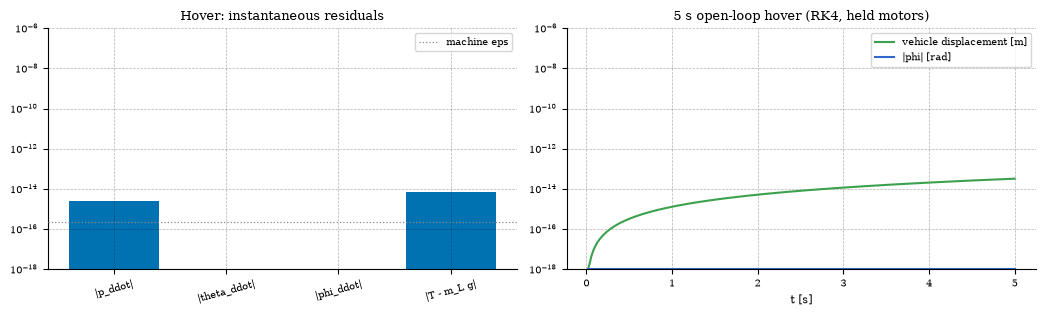

In [ ]:
# Static copy of the panel's default state, for viewers without widgets.
fig = draw_hover(m_L=4.0, l=2.0, d=D_CANON); plt.show()

### 5.2 Power balance (H2)
Two checks. (a) The **instantaneous** identity $\dot E - P_{\rm in}$ at 300 random states (all signs, rates, motor states, $d$, $l$, $m_L$): this isolates the algebra. (b) A **trajectory** with a sinusoidal motor command: $E(t)-E(0)$ against $\int_0^tP_{\rm in}\,dt'$. The integral uses the trapezoid rule on the tick samples, so its own error shrinks with $T_s^2$; RK4 is run with $N=10$ substeps in all cases.

In [5]:
def instantaneous_energy_residual(n=300, seed=0):
    rng = np.random.default_rng(seed); worst = 0.0
    for _ in range(n):
        pl = PayloadParams(rng.uniform(1, 6), rng.uniform(0.5, 3), rng.uniform(0, 0.3)); plant = QuadLoadPend(VEH, pl)
        st = QuadLoadState(QuadState(*rng.normal(size=4), rng.uniform(-.4, .4), rng.normal() * .5,
                                     rng.uniform(.2, .9), rng.uniform(.2, .9)), rng.uniform(-.5, .5), rng.normal())
        P_in = input_power(plant, st)
        worst = max(worst, abs(dE_dt_from_accelerations(plant, st) - P_in) / (1.0 + abs(P_in)))
    return worst

def energy_trajectory(m_L, l, d, T_s, N=10, T_end=2.0, phi0=0.2, amp=0.04):
    pl = PayloadParams(m_L, l, d); plant = QuadLoadPend(VEH, pl); tm = Timing(T_s, N); c0 = hover_c(m_L)
    st = QuadLoadState(QuadState(0, 0, 0, 0, 0, 0, c0, c0), phi0, 0.0)
    n = int(round(T_end / T_s)); E = [total_energy(pl, st)]; P_ = [input_power(plant, st)]
    for k in range(n):
        t = k * T_s
        u = (c0 * (1 + amp * math.sin(2 * math.pi * 0.7 * t)), c0 * (1 - amp * math.sin(2 * math.pi * 0.7 * t + 0.5)))
        st = plant.step(st, u, tm).state
        E.append(total_energy(pl, st)); P_.append(input_power(plant, st))
    t = np.arange(n + 1) * T_s; E = np.array(E); P_ = np.array(P_)
    W = cumulative_trapezoid(P_, t, initial=0.0)
    return t, E - E[0], W

ID_RESID = instantaneous_energy_residual()

def draw_energy(m_L=4.0, l=2.0, d=D_CANON, T_s_inv=50):
    t, dE, W = energy_trajectory(m_L, l, d, 1.0 / T_s_inv)
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
    ax[0].plot(t, dE, **style.arm_style("pid_ff", label=r"$E(t)-E(0)$")); ax[0].plot(t, W, **style.arm_style("mrac", linestyle="-", label=r"$\int P_{in}\,dt$"))
    ax[0].set_title("Energy change vs input work"); ax[0].set_xlabel("t [s]"); ax[0].set_ylabel("J"); ax[0].legend(fontsize=7)
    ax[1].plot(t, dE - W, color="#0072B2"); ax[1].set_title("Balance residual [J]"); ax[1].set_xlabel("t [s]")
    invs = [25, 50, 100, 200, 400]; errs = []
    for iv in invs:
        tt, dd, ww = energy_trajectory(m_L, l, d, 1.0 / iv); errs.append(np.max(np.abs(dd - ww)))
    ax[2].loglog(invs, errs, "o-", color="#0072B2", label="max |residual|")
    ax[2].loglog(invs, errs[2] * (np.array(invs) / invs[2]) ** -2.0, **style.arm_style("ref", label=r"slope $-2$ ($T_s^2$)"))
    ax[2].set_xlabel(r"$1/T_s$ [Hz]"); ax[2].set_title("Residual vs sampling (trapezoid)"); ax[2].legend(fontsize=7)
    for a_ in ax: a_.grid(True, alpha=0.3)
    fig.suptitle("Instantaneous identity, max over 300 random states: %.2e (relative)" % ID_RESID, fontsize=8)
    fig.tight_layout(); return fig

panel_energy = widgets.param_panel({
    "m_L": ("slider", 1.0, 8.0, 0.5, 4.0, "m_L [kg]"),
    "l": ("slider", 0.5, 3.0, 0.25, 2.0, "l [m]"),
    "d": ("slider", 0.0, 0.5, 0.005, D_CANON, "d [m] (canonical 0.3795)"),
    "T_s_inv": ("dropdown", [25, 50, 100, 200], 50, "1/T_s [Hz] (panel 1-2)"),
}, draw_energy)

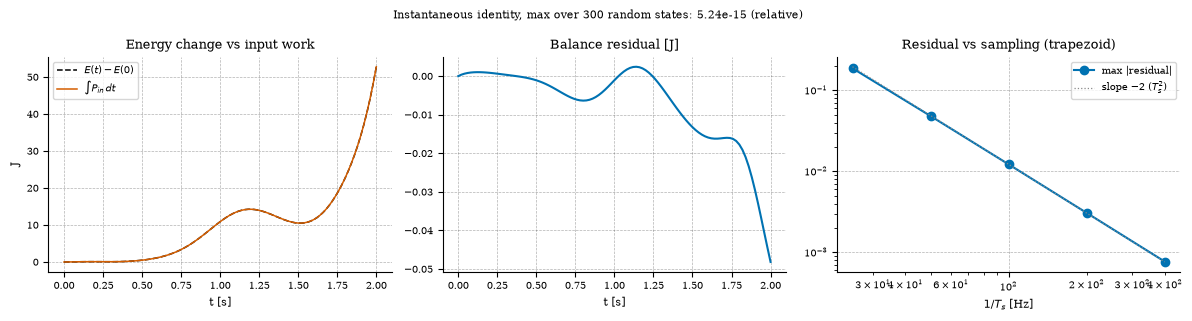

In [ ]:
# Static copy of the panel's default state, for viewers without widgets.
fig = draw_energy(m_L=4.0, l=2.0, d=D_CANON, T_s_inv=50); plt.show()

### 5.3 Two swing frequencies (H3)
Small oscillation $\phi_0=0.05$ rad. Model (i): vehicle held fixed (the swing ODE alone). Model (ii): the full plant `QuadLoadPend` with $d=0$, equal motor commands at the combined-mass hover value, vehicle free. Frequencies are measured from zero crossings and compared with the closed forms. The residual of the first comparison is the finite-amplitude shift $\approx\phi_0^2/16\cdot\omega$.

In [6]:
def swing_frequencies(m_L, l, phi0=0.05):
    f = lambda t, y: [y[1], -(G / l) * np.sin(y[0])]
    s = solve_ivp(f, [0, 20], [phi0, 0.0], rtol=1e-11, atol=1e-13, dense_output=True)
    t1 = np.linspace(0, 20, 20001); y1 = s.sol(t1)[0]
    w_fixed, n1 = freq_from_crossings(t1, y1)
    pl = PayloadParams(m_L, l, 0.0); plant = QuadLoadPend(VEH, pl); c0 = hover_c(m_L)
    st = hover_state(m_L, phi0); tm = Timing(1 / 200, 10); ph = [st.phi]
    for k in range(4000):
        st = plant.step(st, (c0, c0), tm).state; ph.append(st.phi)
    t2 = np.arange(len(ph)) / 200.0
    w_free, n2 = freq_from_crossings(t2, np.array(ph))
    return dict(t1=t1, y1=y1, t2=t2, y2=np.array(ph), w_fixed=w_fixed, w_free=w_free,
                pred_fixed=math.sqrt(G / l), pred_free=math.sqrt(G / l * (1 + m_L / VEH.m)), n=(n1, n2))

def draw_freq(m_L=4.0, l=2.0):
    r = swing_frequencies(m_L, l)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    ax[0].plot(r["t1"][:6000], np.degrees(r["y1"][:6000]), label=r"vehicle fixed, $\omega=%.4f$ (pred. %.4f)" % (r["w_fixed"], r["pred_fixed"]), color="#0072B2")
    ax[0].plot(r["t2"][:1500], np.degrees(r["y2"][:1500]), label=r"vehicle free, $\omega=%.4f$ (pred. %.4f)" % (r["w_free"], r["pred_free"]), color="#D55E00")
    ax[0].set_xlabel("t [s]"); ax[0].set_ylabel(r"$\phi$ [deg]"); ax[0].set_title("Swing after a small release"); ax[0].legend(fontsize=7)
    ax[1].bar(["fixed", "free"], [r["w_fixed"] / r["pred_fixed"] - 1, r["w_free"] / r["pred_free"] - 1], color=["#0072B2", "#D55E00"])
    ax[1].axhline(0, color="k", lw=0.6); ax[1].set_title("relative error of the measured frequency")
    ax[1].text(0.5, 0.9, r"ratio free/fixed = %.6f, $\sqrt{1+m_L/m_q}$ = %.6f" % (r["w_free"] / r["w_fixed"], math.sqrt(1 + m_L / VEH.m)),
               transform=ax[1].transAxes, ha="center", fontsize=8)
    for a_ in ax: a_.grid(True, alpha=0.3)
    fig.tight_layout(); return fig

panel_freq = widgets.param_panel({
    "m_L": ("slider", 1.0, 8.0, 0.5, 4.0, "m_L [kg]"),
    "l": ("slider", 0.5, 3.0, 0.25, 2.0, "l [m]"),
}, draw_freq)

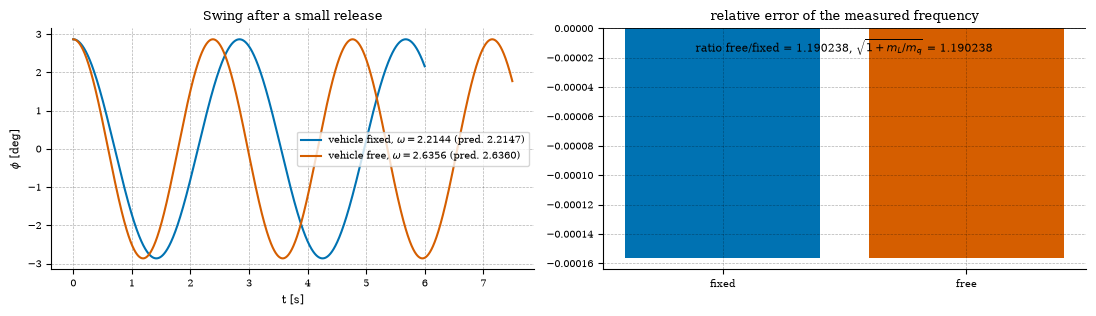

In [ ]:
# Static copy of the panel's default state, for viewers without widgets.
fig = draw_freq(m_L=4.0, l=2.0); plt.show()

### 5.4 Fact 1 offline: prescribed vehicle motion (H4)
The vehicle follows a rest-to-rest **minimum-jerk** lateral transfer of $\Delta y$ in $T_f$ seconds with the quasi-static tilt $\theta=-a_y/g$ (so $\dot\theta=-j_y/g$, $\ddot\theta=-s_y/g$, closed form). $\phi(t)$ is integrated from the swing equation with `tension_and_swing`; $T$ comes from the same call. Three payload masses are overlaid: the $\phi$ curves coincide, the tension scales with $m_L$. Move the $l$ slider: the swing changes.

In [7]:
def prescribed_swing(m_L, l, d, delta=3.0, T_f=3.0, T_end=9.0, phi0=0.0):
    pl = PayloadParams(m_L, l, d)
    def veh(t):
        p, v, a, j, s = min_jerk(t, delta, T_f)
        return float(a), float(-a / G), float(-j / G), float(-s / G)        # a_y, theta, theta_dot, theta_ddot
    def rhs(t, y):
        a_y, th, thd, thdd = veh(t)
        T, ph_dd = tension_and_swing(G, pl, th, y[0], thd, y[1], (a_y, 0.0), thdd)
        return [y[1], ph_dd]
    t = np.linspace(0, T_end, 901)
    s = solve_ivp(rhs, [0, T_end], [phi0, 0.0], t_eval=t, rtol=1e-11, atol=1e-13)
    Tt = []
    for i, ti in enumerate(t):
        a_y, th, thd, thdd = veh(ti)
        Tt.append(tension_and_swing(G, pl, th, s.y[0][i], thd, s.y[1][i], (a_y, 0.0), thdd)[0])
    p, v, a, j, sn = min_jerk(t, delta, T_f)
    return dict(t=t, phi=s.y[0], phi_dot=s.y[1], T=np.array(Tt), a_y=a, y=p)

def draw_fact1(l=2.0, d=0.0, delta=3.0, T_f=3.0):
    masses = (2.0, 4.0, 6.0); runs = {m: prescribed_swing(m, l, d, delta, T_f) for m in masses}
    l_other = 1.0 if l != 1.0 else 3.0
    other = prescribed_swing(4.0, l_other, d, delta, T_f)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4)); cols = {2.0: "#56B4E9", 4.0: "#0072B2", 6.0: "#003A5D"}
    for m, r in runs.items():
        ax[0].plot(r["t"], np.degrees(r["phi"]), color=cols[m], lw=2.4 - 0.6 * masses.index(m), label=f"$m_L$={m:g} kg")
        ax[1].plot(r["t"], r["T"], color=cols[m], label=f"$m_L$={m:g} kg")
    ax[0].plot(other["t"], np.degrees(other["phi"]), **style.arm_style("ref", label=f"$m_L$=4 kg, $l$={l_other:g} m"))
    ax[0].set_title(r"$\phi(t)$: identical for 2, 4, 6 kg; changes with $l$"); ax[0].set_ylabel(r"$\phi$ [deg]")
    ax[1].set_title(r"Tension $T(t)$: scales with $m_L$"); ax[1].set_ylabel("T [N]")
    ref = runs[4.0]; ax[2].plot(ref["t"], ref["a_y"], color="k"); ax[2].set_title("prescribed $a_y(t)$ (min-jerk transfer)"); ax[2].set_ylabel("m/s$^2$")
    dphi = max(np.max(np.abs(runs[m]["phi"] - runs[4.0]["phi"])) for m in masses)
    dT = max(np.max(np.abs(runs[m]["T"] / m - runs[4.0]["T"] / 4.0)) for m in masses)
    for a_ in ax:
        a_.set_xlabel("t [s]"); a_.grid(True, alpha=0.3)
    ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
    fig.suptitle(r"max over masses of $|\phi-\phi_{4\,kg}|$ = %.2e rad;  max $|T/m_L - T_{4kg}/4|$ = %.2e N/kg" % (dphi, dT), fontsize=8)
    fig.tight_layout(); return fig

panel_fact1 = widgets.param_panel({
    "l": ("slider", 0.5, 3.0, 0.25, 2.0, "l [m]"),
    "d": ("slider", 0.0, 0.5, 0.005, 0.0, "d [m]"),
    "delta": ("slider", 1.0, 5.0, 0.5, 3.0, "transfer [m]"),
    "T_f": ("slider", 1.5, 6.0, 0.5, 3.0, "duration T_f [s]"),
}, draw_fact1)

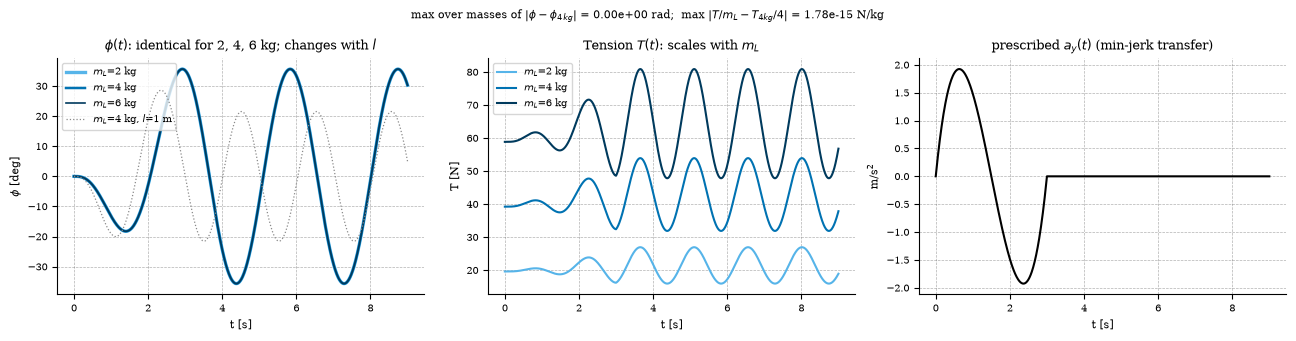

In [ ]:
# Static copy of the panel's default state, for viewers without widgets.
fig = draw_fact1(l=2.0, d=0.0, delta=3.0, T_f=3.0); plt.show()

### 5.5 Contrast: the same open-loop commands on the plant
Now the vehicle is **not** prescribed. The motor commands are the same for every payload, i.e. the same command history $f(t),\tau(t)$ (hover value for 4 kg, plus a short differential pulse that tilts the vehicle); the vehicle now moves differently for each $m_L$ (see $z$), and with $d>0$ the cable torque $dT\sigma$ makes even the attitude mass-dependent, so $\phi(t)$ differs. **Set $d=0$ and the curves collapse again**: at $d=0$ the swing equation reads $l\ddot\phi=-(f/m_q)\,t(\phi)^{\top}b(\theta)$ (the planar form of the Sreenath et al. taut equations, quoted in MQP §5.7, limits), which contains no $m_L$ either, and $\theta$ is not driven by the cable. So, **for the same command history $f(t),\tau(t)$**, the swing is mass-free at $d=0$; the mass dependence of a closed loop enters through feedback on the vehicle position (notebook 06) and through $d>0$.

In [8]:
def plant_response(m_L, l, d, T_end=3.0):
    pl = PayloadParams(m_L, l, d); plant = QuadLoadPend(VEH, pl); c0 = hover_c(4.0)
    st = hover_state(4.0); t = [0.0]; phi = [0.0]; z = [0.0]; y = [0.0]
    try:
        for k in range(int(T_end / T_S)):
            du = 0.01 * c0 if k < 5 else (-0.01 * c0 if k < 10 else 0.0)   # tilt pulse, then counter pulse (omega back to 0)
            st = plant.step(st, (c0 - du, c0 + du), TIMING).state
            t.append((k + 1) * T_S); phi.append(st.phi); z.append(st.quad.p_z); y.append(st.quad.p_y)
    except TautDomainExit:
        pass
    return np.array(t), np.array(phi), np.array(z), np.array(y)

def draw_contrast(l=2.0, d=D_CANON):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2)); cols = {2.0: "#56B4E9", 4.0: "#0072B2", 6.0: "#003A5D"}
    for m in (2.0, 4.0, 6.0):
        t, phi, z, y = plant_response(m, l, d)
        ax[0].plot(t, np.degrees(phi), color=cols[m], label=f"$m_L$={m:g} kg"); ax[1].plot(t, z, color=cols[m]); ax[2].plot(t, y, color=cols[m])
    ax[0].set_title(r"$\phi(t)$: now depends on $m_L$"); ax[0].set_ylabel(r"$\phi$ [deg]"); ax[1].set_title("vehicle $z$ [m] (hover thrust for 4 kg)"); ax[2].set_title("vehicle $y$ [m]")
    for a_ in ax:
        a_.set_xlabel("t [s]"); a_.grid(True, alpha=0.3)
    ax[0].legend(fontsize=7); fig.tight_layout(); return fig

panel_contrast = widgets.param_panel({
    "l": ("slider", 0.5, 3.0, 0.25, 2.0, "l [m]"),
    "d": ("slider", 0.0, 0.5, 0.005, D_CANON, "d [m] (canonical 0.3795)"),
}, draw_contrast)

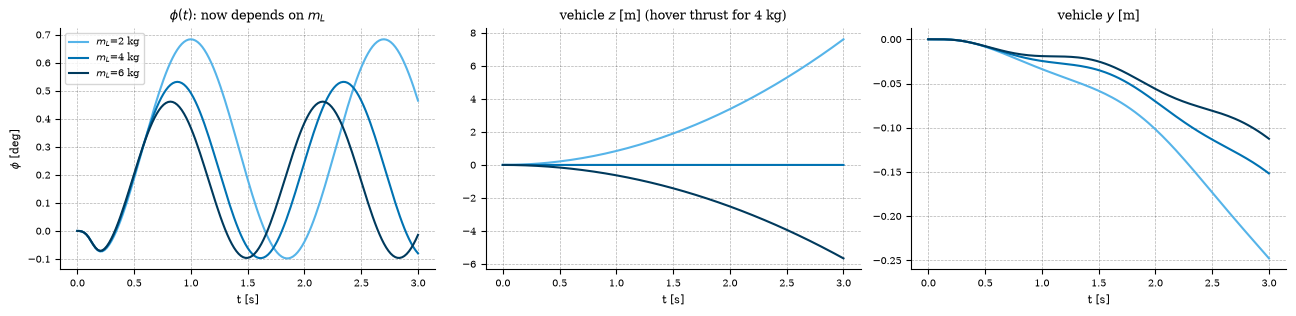

In [ ]:
# Static copy of the panel's default state, for viewers without widgets.
fig = draw_contrast(l=2.0, d=D_CANON); plt.show()

### 5.6 Accelerating frame and the taut-domain exit (H5)
Left: for a prescribed lateral acceleration $a_y$ (with $\theta=0$, $d=0$, $\dot\phi=0$) the dimensionless tension $T/(m_Lg)=\cos\phi-\sin\phi\,a_y/g$ against the cable angle; the zero crossing $\phi=\operatorname{arccot}(a_y/g)$ is the slack boundary. The vertical marker is the equilibrium lag $\phi_{eq}=-\arctan(a_y/g)$ (where $\ddot\phi=0$), computed by the model and by the closed form. Right: the plant under a **thrust cut** from hover at cable angle $\phi_0$: the model keeps $T>0$ while the pendulum swings, and raises `TautDomainExit` when the tension reaches exactly zero (here only at $\phi_0=0$, $\dot\phi_0=0$).

In [9]:
def lag_angle_check(a_y, a_z=0.0, m_L=4.0, l=2.0):
    pl = PayloadParams(m_L, l, 0.0)
    phi_eq = -math.atan2(a_y, G + a_z)
    T, phi_dd = tension_and_swing(G, pl, 0.0, phi_eq, 0.0, 0.0, (a_y, a_z), 0.0)
    return phi_eq, abs(phi_dd), abs(T - m_L * math.hypot(a_y, G + a_z))

def thrust_cut(phi0, dphi0, t_cut=0.1, T_end=1.5, level=0.0):
    pl = PayloadParams(4.0, 2.0, 0.0); plant = QuadLoadPend(VEH, pl); c0 = hover_c(4.0)
    st0 = hover_state(4.0, phi0); st = QuadLoadState(st0.quad, phi0, dphi0)
    t = [0.0]; T = [plant.accelerations(st).tension]; msg = None
    try:
        for k in range(int(T_end / T_S)):
            c = c0 if (k * T_S) < t_cut else level * c0
            r = plant.step(st, (c, c), TIMING); st = r.state
            t.append((k + 1) * T_S); T.append(r.end_tension)
    except TautDomainExit as e:
        msg = str(e)
    return np.array(t), np.array(T), msg

def draw_slack(a_over_g=0.5, phi0=0.5, dphi0=0.0, level=0.0):
    a_y = a_over_g * G; phis = np.linspace(-1.2, 1.2, 400)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    for k, col in zip((0.0, 0.5, 1.0, 2.0), ("#999999", "#56B4E9", "#0072B2", "#003A5D")):
        ax[0].plot(np.degrees(phis), np.cos(phis) - np.sin(phis) * k, color=col, label=f"$a_y/g$={k:g}")
    ax[0].plot(np.degrees(phis), np.cos(phis) - np.sin(phis) * a_over_g, color="#D55E00", lw=2.2, label=f"selected $a_y/g$={a_over_g:g}")
    phi_eq, resid_phidd, resid_T = lag_angle_check(a_y)
    ax[0].axhline(0, color=style.SLACK_COLOR, lw=0.9, label="slack"); ax[0].axvline(np.degrees(phi_eq), **style.arm_style("ref", label=r"$\phi_{eq}$"))
    ax[0].set_xlabel(r"$\phi$ [deg]"); ax[0].set_ylabel(r"$T/(m_Lg)$"); ax[0].set_ylim(-1.5, 1.6)
    ax[0].set_title(r"$\phi_{eq}=%.3f$ rad: model $|\ddot\phi|$=%.1e, $|T-T_{cf}|$=%.1e" % (phi_eq, resid_phidd, resid_T), fontsize=8); ax[0].legend(fontsize=6, loc="lower left")
    t, T, msg = thrust_cut(phi0, dphi0, level=level)
    ax[1].plot(t, T, **style.arm_style("pid_ff", label="T(t), thrust cut at 0.1 s"))
    ax[1].axhline(0, color=style.SLACK_COLOR, lw=0.9); ax[1].set_xlabel("t [s]"); ax[1].set_ylabel("T [N]")
    ax[1].set_title("plant: " + ("TautDomainExit raised (T not > 0)" if msg else "stays taut (min T = %.2f N)" % T.min()), fontsize=8)
    for a_ in ax: a_.grid(True, alpha=0.3)
    ax[1].legend(fontsize=7); fig.tight_layout(); return fig

panel_slack = widgets.param_panel({
    "a_over_g": ("slider", 0.0, 2.0, 0.1, 0.5, "a_y / g"),
    "phi0": ("slider", 0.0, 1.0, 0.1, 0.5, "phi_0 [rad]"),
    "dphi0": ("slider", 0.0, 2.0, 0.5, 0.0, "dphi_0 [rad/s]"),
    "level": ("slider", 0.0, 1.0, 0.25, 0.0, "thrust after cut (x hover)"),
}, draw_slack)

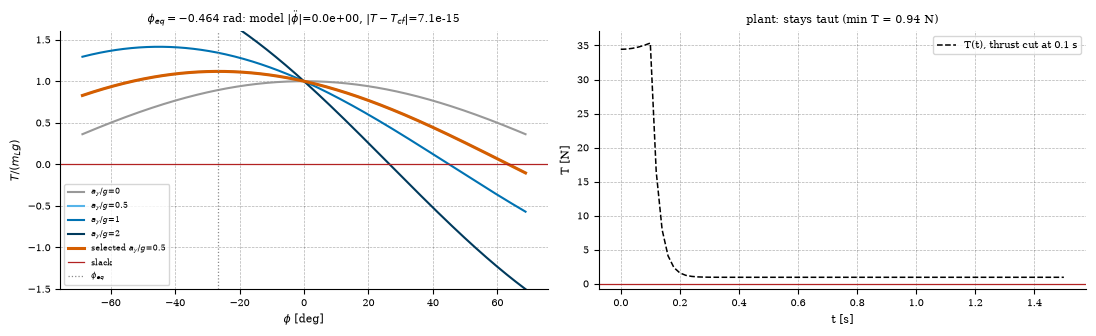

In [ ]:
# Static copy of the panel's default state, for viewers without widgets.
fig = draw_slack(a_over_g=0.5, phi0=0.5, dphi0=0.0, level=0.0); plt.show()

## 6. Observations
The numbers below are computed in the cell that follows (nothing is typed in by hand).

In [10]:
rows = []
worst_hover = max(max(hover_residuals(m, l, d).values()) for m in (1, 2, 4, 6, 8) for l in (0.5, 1, 2, 3) for d in (0, 0.1, D_CANON))
rows.append(dict(check="H1 hover residual (max over 60 conditions)", value=worst_hover, prediction="~1e-14", tolerance=1e-9, ok=worst_hover < 1e-9))
rows.append(dict(check="H2a instantaneous dE/dt - P_in (relative, 300 random states)", value=ID_RESID, prediction="~1e-15", tolerance=1e-10, ok=ID_RESID < 1e-10))
errs = {}
for iv in (50, 200):
    t_, dd_, ww_ = energy_trajectory(4.0, 2.0, D_CANON, 1.0 / iv); errs[iv] = float(np.max(np.abs(dd_ - ww_)))
slope = math.log(errs[50] / errs[200]) / math.log(4.0)
rows.append(dict(check="H2b trajectory balance residual at 50 Hz [J]", value=errs[50], prediction="quadrature error", tolerance=0.5, ok=errs[50] < 0.5))
rows.append(dict(check="H2b convergence order of the residual (50 -> 200 Hz)", value=slope, prediction="2 (trapezoid)", tolerance=0.2, ok=abs(slope - 2.0) < 0.2))
freq_rows = []
for m, l in ((2, 1), (4, 2), (6, 3), (4, 1)):
    r = swing_frequencies(m, l)
    freq_rows.append(dict(m_L=m, l=l, fixed_rel_err=r["w_fixed"] / r["pred_fixed"] - 1, free_rel_err=r["w_free"] / r["pred_free"] - 1,
                          ratio_rel_err=(r["w_free"] / r["w_fixed"]) / math.sqrt(1 + m / VEH.m) - 1))
fr = pd.DataFrame(freq_rows)
rows.append(dict(check="H3 fixed-vehicle frequency, max rel. error", value=float(fr.fixed_rel_err.abs().max()), prediction="at most phi0^2/16 = 1.6e-4", tolerance=5e-4, ok=float(fr.fixed_rel_err.abs().max()) < 5e-4))
rows.append(dict(check="H3 free-vehicle frequency, max rel. error", value=float(fr.free_rel_err.abs().max()), prediction="at most 5e-4", tolerance=5e-4, ok=float(fr.free_rel_err.abs().max()) < 5e-4))
rows.append(dict(check="H3 ratio free/fixed vs sqrt(1+m_L/m_q), max rel. error", value=float(fr.ratio_rel_err.abs().max()), prediction="below 1e-5", tolerance=1e-5, ok=float(fr.ratio_rel_err.abs().max()) < 1e-5))
ref_run = prescribed_swing(4.0, 2.0, D_CANON)
dphi = max(np.max(np.abs(prescribed_swing(m, 2.0, D_CANON)["phi"] - ref_run["phi"])) for m in (2.0, 6.0))
dphi_l = np.max(np.abs(prescribed_swing(4.0, 1.0, D_CANON)["phi"] - prescribed_swing(4.0, 3.0, D_CANON)["phi"]))
ref_plant = plant_response(4.0, 2.0, D_CANON)[1]
dphi_plant = max(np.max(np.abs(plant_response(m, 2.0, D_CANON)[1] - ref_plant)) for m in (2.0, 6.0))
ref_plant0 = plant_response(4.0, 2.0, 0.0)[1]
dphi_plant0 = max(np.max(np.abs(plant_response(m, 2.0, 0.0)[1] - ref_plant0)) for m in (2.0, 6.0))
rows.append(dict(check="H4 prescribed vehicle: max |phi(2 or 6 kg) - phi(4 kg)| [rad]", value=float(dphi), prediction="0 (structural)", tolerance=1e-12, ok=dphi < 1e-12))
rows.append(dict(check="H4 prescribed vehicle: max |phi(l=1) - phi(l=3)| [rad]", value=float(dphi_l), prediction="clearly > 0", tolerance=1e-2, ok=dphi_l > 1e-2))
rows.append(dict(check="H4 open-loop plant, d=canonical: max |phi(2 or 6 kg) - phi(4 kg)| [rad]", value=float(dphi_plant), prediction="clearly above zero", tolerance=1e-4, ok=dphi_plant > 1e-4))
rows.append(dict(check="H4 open-loop plant, d=0: max |phi(2 or 6 kg) - phi(4 kg)| [rad]", value=float(dphi_plant0), prediction="0 (exact property at d=0)", tolerance=1e-10, ok=dphi_plant0 < 1e-10))
lag = max(max(lag_angle_check(a)[1], lag_angle_check(a)[2]) for a in (0.0, 1.0, 3.0, -2.0, 6.0))
rows.append(dict(check="H5 lag angle and tension closed form (max residual)", value=float(lag), prediction="~1e-14", tolerance=1e-9, ok=lag < 1e-9))
t_, T_, msg = thrust_cut(0.0, 0.0)
rows.append(dict(check="H5 thrust cut at phi0=0: TautDomainExit raised (1 = yes)", value=float(msg is not None), prediction="1 (T = 0 exactly)", tolerance=0.5, ok=msg is not None))
TABLE = pd.DataFrame(rows)
display(Markdown("**All hypotheses within tolerance: %s**   (vehicle parameters: %s)" % (bool(TABLE.ok.all()), "canonical_offline_params()")))

**All hypotheses within tolerance: True**   (vehicle parameters: canonical_offline_params())

## 7. Quantitative table

In [11]:
fmt = TABLE.copy()
fmt["value"] = fmt["value"].map(lambda v: "%.3e" % v)
fmt["tolerance"] = fmt["tolerance"].map(lambda v: "%.0e" % v)
display(fmt.style.format(escape="html").hide(axis="index"))
display(Markdown("Frequency detail (relative errors):"))
display(fr.style.format({c: "{:.2e}" for c in fr.columns[2:]}).hide(axis="index"))

check,value,prediction,tolerance,ok
H1 hover residual (max over 60 conditions),1.421e-14,~1e-14,1e-09,True
"H2a instantaneous dE/dt - P_in (relative, 300 random states)",5.235e-15,~1e-15,1e-10,True
H2b trajectory balance residual at 50 Hz [J],4.816e-02,quadrature error,5e-01,True
H2b convergence order of the residual (50 -> 200 Hz),1.986e+00,2 (trapezoid),2e-01,True
"H3 fixed-vehicle frequency, max rel. error",1.562e-04,at most phi0^2/16 = 1.6e-4,5e-04,True
"H3 free-vehicle frequency, max rel. error",1.563e-04,at most 5e-4,5e-04,True
"H3 ratio free/fixed vs sqrt(1+m_L/m_q), max rel. error",2.523e-09,below 1e-5,1e-05,True
H4 prescribed vehicle: max |phi(2 or 6 kg) - phi(4 kg)| [rad],0.000e+00,0 (structural),1e-12,True
H4 prescribed vehicle: max |phi(l=1) - phi(l=3)| [rad],1.033e+00,clearly > 0,1e-02,True
"H4 open-loop plant, d=canonical: max |phi(2 or 6 kg) - phi(4 kg)| [rad]",1.030e-02,clearly above zero,1e-04,True


Frequency detail (relative errors):

m_L,l,fixed_rel_err,free_rel_err,ratio_rel_err
2,1,-1.56e-04,-1.56e-04,-2.52e-09
4,2,-1.56e-04,-1.56e-04,-1.01e-09
6,3,-1.56e-04,-1.56e-04,-1.02e-09
4,1,-1.56e-04,-1.56e-04,-2.20e-09


## 8. Interpretation (EXPLORATORY)

* The eliminated model passes the consistency checks of section 6 at the stated tolerances. These are checks of **algebra and code consistency of a reduced model**, not evidence about the physical or the Pymunk system (MQP §0, status, subsection "What is not claimed").
* The power-balance check is deliberately *independent* of the tension formula (the payload acceleration is rebuilt from the kinematics), so it would catch a sign or factor error in the elimination of section 4.4 above (MQP §5.6, elimination).
* **Fact 1 is a property of the swing equation**, not of the controller: for a prescribed vehicle path $\phi$ is mass-free. The contrast panel shows that once the vehicle responds to the payload (here through the cable torque at $d>0$) the swing becomes mass-dependent; at $d=0$, for the same command history $f(t),\tau(t)$, it stays mass-free (the swing equation then involves only $f/m_q$ and $\theta$). So in a closed loop with a mass-blind feedforward (notebook 06, arm 1) any mass dependence of $\phi$ comes *through the vehicle motion that the feedback produces* and, for $d>0$, also through the cable torque $dT\sigma$ on the attitude, not through the cable kinematics.
* The two frequencies differ by $\sqrt{1+m_L/m_q}$ (a free vehicle sways with the payload). Which of them is the relevant "swing time scale" for a controller that holds the attachment point stiffly depends on the closed loop; notebook 06 derives it for the attitude loop.
* Limits: point-mass payload, rigid massless cable, no drag or wind, no slack mode. The Pymunk chain has 8 segments and a different slack behaviour (MQP §1.4, what later waves ask: wave W3 of the MRAC plan asks whether this reduction is adequate for the Pymunk chain; nothing here answers it).


## 9. Decisions and next steps

### Decisions (Javier, 2026-11-24, after the professor meeting)

| Item | Decision |
|---|---|
| NB05 | The canonical attachment offset $d=0.3795$ m (half the vehicle height, the choice made when the offline model was built, recorded in the provenance banner printed by the setup cell) is the right offline value for arms 1-3. Notebook 05 still sweeps $d$ only to show that it does not affect Fact 1. |
| Meeting Q1 (first question of the professor meeting) | The A0 reference (MQP §1.2, architecture A0) carries the **nominal payload** (4 kg, 2 m), the load on which the law was tuned (see notebook 07). |
| Meeting Q3 (third question of the professor meeting) | The next comparison is an offline grid of PID+FF (with and without the swing laws) under **vehicle-parameter mismatch** (notebook 08). |

### Next steps

* **Notebook 06:** arms 1-2 (PID+FF with a mass-blind FF, the linear damper) on this plant, with the damper derived step by step in `sympy`, and the new subsection on the non-minimum-phase zero that the attachment offset puts in the torque-to-swing path.
* **Notebook 08:** the offline vehicle-mismatch grid (mass, inertia, arm, motor asymmetry; one at a time, nominal load).
* **Notebook 07:** arm 3 (the softer law with the payload-aware MRAC law), formulation and a PRELIMINARY run; the next step there is the nominal-payload reference.
* No claim in this notebook should be quoted outside the logbook without the EXPLORATORY / offline / PROXY label.
